# Tugas Kelompok Pemrosesan Teks
**Universitas Teknologi Yogyakarta (UTY)**
*Fakultas Sains & Teknologi • Program Studi Informatika*

In [1]:
!pip install -q youtube-comment-downloader Sastrawi nltk pandas matplotlib seaborn

import os, re, string, hashlib, itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk import ngrams, FreqDist
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

for res in ['punkt', 'punkt_tab', 'stopwords']:
    nltk.download(res, quiet=True)

sns.set_theme(style="whitegrid")
pd.set_option('display.max_colwidth', 80)



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Pengumpulan 500 Data Teks dari YouTube


In [2]:
from youtube_comment_downloader import YoutubeCommentDownloader, SORT_BY_POPULAR

url = "https://www.youtube.com/watch?v=ToZSRkAybKc"
downloader = YoutubeCommentDownloader()
comments = downloader.get_comments_from_url(url, sort_by=SORT_BY_POPULAR)

data = []
for c in itertools.islice(comments, 600):
    teks = c.get('text', '')
    if teks and teks.strip():
        data.append({
            'author': c.get('author'),
            'text': teks.strip(),
            'votes': c.get('votes', 0),
            'time': c.get('time', '')
        })

df = pd.DataFrame(data)
df = df.drop_duplicates(subset=['text']).reset_index(drop=True)

# Pastikan minimal 500 data teks
if len(df) > 520:
    df = df.iloc[:520].copy()

df.info()
df[['author', 'text', 'votes']].head()


<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   author  520 non-null    str  
 1   text    520 non-null    str  
 2   votes   520 non-null    str  
 3   time    520 non-null    str  
dtypes: str(4)
memory usage: 16.4 KB


,author,text,votes
0,@OppoAs-lb6me,"Kalau tidak membuat laporan palsu ya tidak dapat jabatan ,,",456
1,@RudiAnto-d9f,"Anggaran di korupsi dan laporan dimanipulasi, luar biasa !!!",102
2,@FeroZhezhe,To the poin!: GAK BISA KERJA!BISANYA KORUPSI!!!!,302
3,@RivkaAnggraeni,Makanya Indonesia selalu menolak bantuan asing Krn takuttt ketahuan,39
4,@HartSltg,Laporan palsu memang sudah menjadi tradisi supaya pimpinan senang,493


## 2. Pemetaan Lima Tahap Text Mining & Anonimisasi Data

| Tahap | Nama Tahap | Deskripsi Penerapan |
| :---: | :--- | :--- |
| 1 | Information Retrieval | Pengambilan ulasan/komentar dari YouTube secara terstruktur |
| 2 | Information Extraction | Ekstraksi fitur regex (mention, emoji, angka) dan anonimisasi identitas |
| 3 | Text Preprocessing | Case folding, pembersihan tanda baca, normalisasi slang, dan stopword removal |
| 4 | Pattern Discovery | Penerapan stemming Sastrawi, pembentukan 15 bigram, dan 10 kolokasi PMI |
| 5 | Knowledge Interpretation | Menganalisis makna keluhan publik dan isu manipulasi anggaran |


In [3]:
# Anonimisasi data menggunakan hashing SHA-256
def anonimkan(nama):
    if not nama or pd.isna(nama):
        return "user_anonymous"
    return "user_" + hashlib.sha256(str(nama).encode('utf-8')).hexdigest()[:8]

df['id_pengguna'] = df['author'].apply(anonimkan)
df[['author', 'id_pengguna', 'text']].head()


,author,id_pengguna,text
0,@OppoAs-lb6me,user_47dd789a,"Kalau tidak membuat laporan palsu ya tidak dapat jabatan ,,"
1,@RudiAnto-d9f,user_611526a3,"Anggaran di korupsi dan laporan dimanipulasi, luar biasa !!!"
2,@FeroZhezhe,user_30a84b72,To the poin!: GAK BISA KERJA!BISANYA KORUPSI!!!!
3,@RivkaAnggraeni,user_071f9562,Makanya Indonesia selalu menolak bantuan asing Krn takuttt ketahuan
4,@HartSltg,user_296cab57,Laporan palsu memang sudah menjadi tradisi supaya pimpinan senang


## 3. Ekstraksi Fitur Regex & Profil Korpus


,Fitur Regex,Total Kemunculan
0,URL Link,0
1,Mention (@),72
2,Hashtag (#),0
3,Emoji Karakter,247
4,Angka Numerik,44


,Metrik Korpus,Nilai
0,Total Dokumen (Komentar),520 komentar
1,Total Kata (Tokens),8194 kata
2,Ukuran Kosakata Unik (Vocabulary),2952 kata unik
3,Lexical Diversity (TTR),0.3603
4,Rata-rata Panjang Karakter,102.60 karakter
5,Rata-rata Panjang Kata,15.76 kata


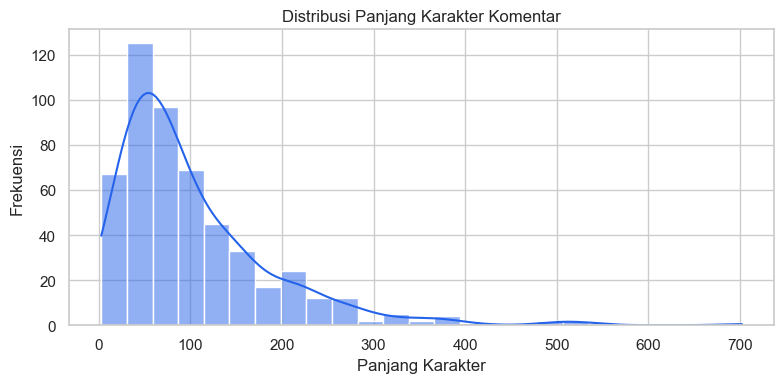

In [4]:
pola_url = re.compile(r'https?://\S+|www\.\S+')
pola_mention = re.compile(r'(?<![\w\.])@\w+')
pola_hashtag = re.compile(r'#\w+')
pola_emoji = re.compile(r'[\U00010000-\U0010ffff]|\u200d|[\u2600-\u27BF]')
pola_angka = re.compile(r'\b\d+\b')

df['fitur_url'] = df['text'].apply(lambda t: len(pola_url.findall(t)))
df['fitur_mention'] = df['text'].apply(lambda t: len(pola_mention.findall(t)))
df['fitur_hashtag'] = df['text'].apply(lambda t: len(pola_hashtag.findall(t)))
df['fitur_emoji'] = df['text'].apply(lambda t: len(pola_emoji.findall(t)))
df['fitur_angka'] = df['text'].apply(lambda t: len(pola_angka.findall(t)))

# Ringkasan Fitur Regex
df_regex = pd.DataFrame({
    'Fitur Regex': ['URL Link', 'Mention (@)', 'Hashtag (#)', 'Emoji Karakter', 'Angka Numerik'],
    'Total Kemunculan': [
        df['fitur_url'].sum(),
        df['fitur_mention'].sum(),
        df['fitur_hashtag'].sum(),
        df['fitur_emoji'].sum(),
        df['fitur_angka'].sum()
    ]
})
display(df_regex)

# Profil Korpus
df['char_length'] = df['text'].apply(len)
df['word_count'] = df['text'].apply(lambda t: len(t.split()))

total_docs = len(df)
total_words = df['word_count'].sum()
all_vocab = set([w.lower() for t in df['text'] for w in t.split()])
lex_div = len(all_vocab) / total_words

df_profil = pd.DataFrame({
    'Metrik Korpus': [
        'Total Dokumen (Komentar)',
        'Total Kata (Tokens)',
        'Ukuran Kosakata Unik (Vocabulary)',
        'Lexical Diversity (TTR)',
        'Rata-rata Panjang Karakter',
        'Rata-rata Panjang Kata'
    ],
    'Nilai': [
        f"{total_docs} komentar",
        f"{total_words} kata",
        f"{len(all_vocab)} kata unik",
        f"{lex_div:.4f}",
        f"{df['char_length'].mean():.2f} karakter",
        f"{df['word_count'].mean():.2f} kata"
    ]
})
display(df_profil)

# Visualisasi Distribusi Panjang Teks
plt.figure(figsize=(8, 4))
sns.histplot(df['char_length'], bins=25, kde=True, color='#2563eb')
plt.title("Distribusi Panjang Karakter Komentar")
plt.xlabel("Panjang Karakter")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()


## 4. Praproses Teks (Pemeliharaan Kata Negasi)
Kata negasi seperti *tidak, bukan, belum, kurang, jangan, tanpa* dipertahankan agar tidak mengubah polaritas sentimen keluhan publik.


In [5]:
# Kamus Leksikon Slang
url_kamus = "https://raw.githubusercontent.com/nasalsabila/kamus-alay/master/colloquial-indonesian-lexicon.csv"
try:
    kamus_df = pd.read_csv(url_kamus)
except Exception:
    kamus_df = pd.read_csv("colloquial-indonesian-lexicon.csv")

kamus = dict(zip(kamus_df['slang'], kamus_df['formal']))
kamus.update({
    'gak': 'tidak', 'ga': 'tidak', 'gk': 'tidak', 'nggak': 'tidak', 'enggak': 'tidak', 'tdk': 'tidak',
    'klo': 'kalau', 'kalo': 'kalau', 'udh': 'sudah', 'udah': 'sudah', 'blm': 'belum', 'bgt': 'banget',
    'krn': 'karena', 'karna': 'karena', 'tp': 'tapi', 'tpi': 'tapi', 'dgn': 'dengan', 'sy': 'saya',
    'jg': 'juga', 'jd': 'jadi', 'jdi': 'jadi', 'sm': 'sama', 'bisaa': 'bisa', 'bkn': 'bukan', 'dn': 'dan'
})

# Stopword: Pertahankan kata negasi
sw_nltk = set(stopwords.words('indonesian'))
sw_sastrawi = set(StopWordRemoverFactory().get_stop_words())
PENTING = {'tidak', 'bukan', 'kurang', 'belum', 'jangan', 'tanpa', 'palsu', 'rusak'}
STOP = (sw_nltk | sw_sastrawi) - PENTING

# Tahap 1: Case Folding
df['step_casefold'] = df['text'].str.lower()

# Tahap 2: Cleaning (Regex)
pola_tanda = re.compile(rf'[{re.escape(string.punctuation)}]')
def bersihkan(teks):
    teks = pola_url.sub(' ', teks)
    teks = pola_mention.sub(' ', teks)
    teks = pola_hashtag.sub(' ', teks)
    teks = pola_emoji.sub(' ', teks)
    teks = re.sub(r'\b([a-z]+)2([a-z]*)\b', r'\1 \1\2', teks)
    teks = re.sub(r'\d+', ' ', teks)
    teks = pola_tanda.sub(' ', teks)
    return re.sub(r'\s+', ' ', teks).strip()

df['step_cleaning'] = df['step_casefold'].apply(bersihkan)

# Tahap 3: Tokenisasi
df['step_tokens'] = df['step_cleaning'].apply(lambda t: [w for w in word_tokenize(t) if w.isalpha()])

# Tahap 4: Normalisasi Slang
def normalisasi_slang(tokens):
    hasil = []
    for tok in tokens:
        tok = re.sub(r'(\w)\1{2,}', r'\1', tok)
        formal = kamus.get(tok, tok)
        for part in formal.split():
            hasil.append(part)
    return hasil

df['step_normal'] = df['step_tokens'].apply(normalisasi_slang)

# Tahap 5: Stopword Removal (Negasi Dipertahankan)
df['step_stopword'] = df['step_normal'].apply(lambda toks: [t for t in toks if t not in STOP and len(t) > 1])

df[['text', 'step_cleaning', 'step_normal', 'step_stopword']].head()


,text,step_cleaning,step_normal,step_stopword
0,"Kalau tidak membuat laporan palsu ya tidak dapat jabatan ,,",kalau tidak membuat laporan palsu ya tidak dapat jabatan,"[kalau, tidak, membuat, laporan, palsu, ya, tidak, dapat, jabatan]","[tidak, laporan, palsu, tidak, jabatan]"
1,"Anggaran di korupsi dan laporan dimanipulasi, luar biasa !!!",anggaran di korupsi dan laporan dimanipulasi luar biasa,"[anggaran, di, korupsi, dan, laporan, dimanipulasi, luar, biasa]","[anggaran, korupsi, laporan, dimanipulasi]"
2,To the poin!: GAK BISA KERJA!BISANYA KORUPSI!!!!,to the poin gak bisa kerja bisanya korupsi,"[tapi, the, poin, tidak, bisa, kerja, bisanya, korupsi]","[the, poin, tidak, kerja, bisanya, korupsi]"
3,Makanya Indonesia selalu menolak bantuan asing Krn takuttt ketahuan,makanya indonesia selalu menolak bantuan asing krn takuttt ketahuan,"[makanya, indonesia, selalu, menolak, bantuan, asing, karena, takut, ketahuan]","[indonesia, menolak, bantuan, asing, takut, ketahuan]"
4,Laporan palsu memang sudah menjadi tradisi supaya pimpinan senang,laporan palsu memang sudah menjadi tradisi supaya pimpinan senang,"[laporan, palsu, memang, sudah, menjadi, tradisi, supaya, pimpinan, senang]","[laporan, palsu, tradisi, pimpinan, senang]"


## 5. Tabel & Analisis Perubahan Kosakata di Tiap Tahap


,Tahap Praproses,Total Token,Ukuran Kosakata (|V|),Reduksi Kosakata (%),Lexical Diversity
0,1. Raw Text,8194,2952,0.00,0.3603
1,2. Case Folding,8194,2952,0.00,0.3603
2,3. Cleaning,8131,2342,20.66,0.2880
3,4. Tokenisasi,8064,2327,21.17,0.2886
4,5. Normalisasi Slang,8065,2134,27.71,0.2646
5,6. Stopword Removal,4715,1802,38.96,0.3822


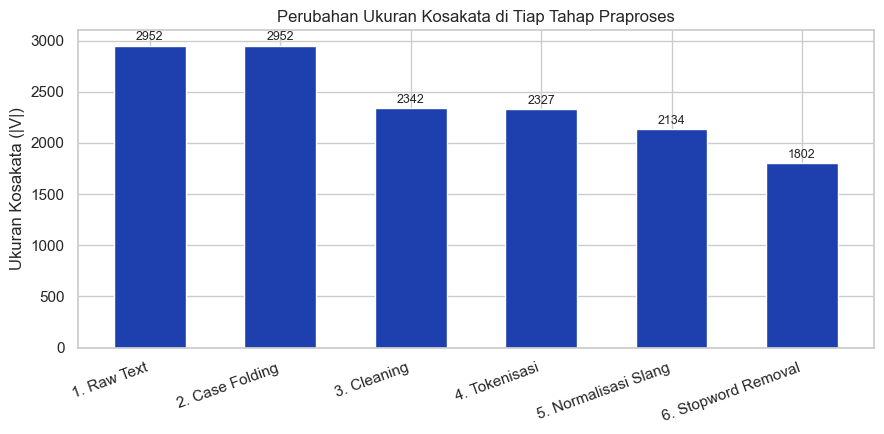

In [6]:
tahapan = [
    ("1. Raw Text", [w.lower() for t in df['text'] for w in t.split()]),
    ("2. Case Folding", [w for t in df['step_casefold'] for w in t.split()]),
    ("3. Cleaning", [w for t in df['step_cleaning'] for w in t.split()]),
    ("4. Tokenisasi", [w for toks in df['step_tokens'] for w in toks]),
    ("5. Normalisasi Slang", [w for toks in df['step_normal'] for w in toks]),
    ("6. Stopword Removal", [w for toks in df['step_stopword'] for w in toks])
]

perubahan = []
vocab_awal = len(set(tahapan[0][1]))

for nama, toks in tahapan:
    n_tok = len(toks)
    vocab = set(toks)
    n_voc = len(vocab)
    pct = ((vocab_awal - n_voc) / vocab_awal) * 100
    div = n_voc / n_tok if n_tok > 0 else 0
    perubahan.append({
        'Tahap Praproses': nama,
        'Total Token': n_tok,
        'Ukuran Kosakata (|V|)': n_voc,
        'Reduksi Kosakata (%)': round(pct, 2),
        'Lexical Diversity': round(div, 4)
    })

df_perubahan = pd.DataFrame(perubahan)
display(df_perubahan)

# Visualisasi Reduksi Kosakata
plt.figure(figsize=(9, 4.5))
bars = plt.bar(df_perubahan['Tahap Praproses'], df_perubahan['Ukuran Kosakata (|V|)'], color='#1e40af', width=0.55)
plt.title("Perubahan Ukuran Kosakata di Tiap Tahap Praproses")
plt.ylabel("Ukuran Kosakata (|V|)")
plt.xticks(rotation=20, ha='right')

for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 20, f"{y}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


## 6. Penerapan Stemming Sastrawi


In [7]:
stemmer = StemmerFactory().create_stemmer()

# Caching kata unik untuk mempercepat proses
kata_unik = set([w for toks in df['step_stopword'] for w in toks])
stem_cache = {w: stemmer.stem(w) for w in kata_unik}

df['step_stemmed'] = df['step_stopword'].apply(
    lambda toks: [stem_cache.get(t, t) for t in toks if len(stem_cache.get(t, t)) > 1]
)

vocab_sebelum = len(kata_unik)
vocab_sesudah = len(set([w for toks in df['step_stemmed'] for w in toks]))
reduksi_stem = ((vocab_sebelum - vocab_sesudah) / vocab_sebelum) * 100

df_stem_stat = pd.DataFrame({
    'Kondisi': ['Sebelum Stemming', 'Setelah Stemming', 'Efisiensi Reduksi'],
    'Nilai': [f"{vocab_sebelum} kata", f"{vocab_sesudah} kata", f"{reduksi_stem:.2f}%"]
})
display(df_stem_stat)


,Kondisi,Nilai
0,Sebelum Stemming,1802 kata
1,Setelah Stemming,1429 kata
2,Efisiensi Reduksi,20.70%


## 7. Temuan 15 Bigram Teratas


,Peringkat,Frasa Bigram,Frekuensi
0,1,lapor palsu,41
1,2,terima lapor,31
2,3,anak buah,16
3,4,lapor lapor,12
4,5,turun lapang,10
5,6,hukum mati,9
6,7,bikin lapor,9
7,8,fakta lapang,8
8,9,lapor senang,7
9,10,rakyat indonesia,7


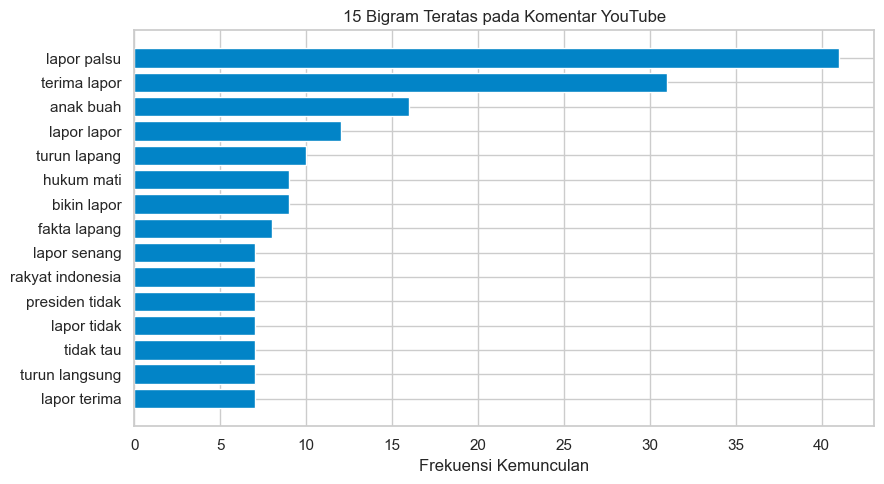

In [8]:
semua_token = [w for toks in df['step_stemmed'] for w in toks]
bigram_list = list(ngrams(semua_token, 2))
fd_bigram = FreqDist(bigram_list)

top15 = fd_bigram.most_common(15)

df_top15 = pd.DataFrame([
    {
        'Peringkat': i,
        'Frasa Bigram': f"{bg[0]} {bg[1]}",
        'Frekuensi': freq
    }
    for i, (bg, freq) in enumerate(top15, 1)
])
display(df_top15)

# Visualisasi Horizontal Bar
plt.figure(figsize=(9, 5))
y_labels = df_top15['Frasa Bigram'][::-1]
x_values = df_top15['Frekuensi'][::-1]
plt.barh(y_labels, x_values, color='#0284c7')
plt.title("15 Bigram Teratas pada Komentar YouTube")
plt.xlabel("Frekuensi Kemunculan")
plt.tight_layout()
plt.show()


## 8. Temuan 10 Kolokasi PMI Teratas


,Peringkat,Kolokasi Frasa,Skor PMI,Frekuensi
0,1,joss jiss,10.2030,4
1,2,kambing hitam,9.8811,5
2,3,ragu joss,9.7880,3
3,4,duduk manis,9.6181,3
4,5,amin amin,9.3550,5
5,6,sengaja pancing,9.2030,3
6,7,kabut asap,8.8811,3
7,8,tanam sawit,8.6181,3
8,9,masuk akal,8.4217,4
9,10,hukum mati,8.2437,9


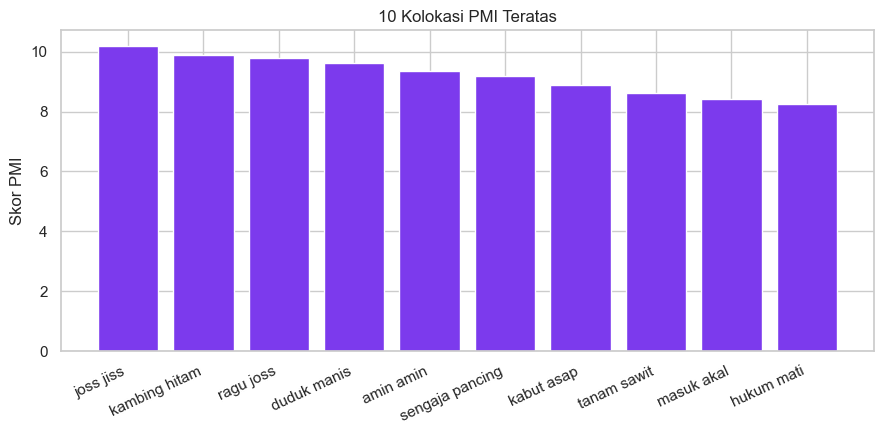

In [9]:
finder = BigramCollocationFinder.from_words(semua_token)
finder.apply_freq_filter(3)

top10_pmi = finder.score_ngrams(BigramAssocMeasures.pmi)[:10]

df_top10_pmi = pd.DataFrame([
    {
        'Peringkat': i,
        'Kolokasi Frasa': f"{bg[0]} {bg[1]}",
        'Skor PMI': round(score, 4),
        'Frekuensi': fd_bigram[bg]
    }
    for i, (bg, score) in enumerate(top10_pmi, 1)
])
display(df_top10_pmi)

# Visualisasi Skor PMI
plt.figure(figsize=(9, 4.5))
plt.bar(df_top10_pmi['Kolokasi Frasa'], df_top10_pmi['Skor PMI'], color='#7c3aed')
plt.title("10 Kolokasi PMI Teratas")
plt.ylabel("Skor PMI")
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()


## 9. Ekspor Korpus CSV Bersih


In [10]:
df_export = df[['id_pengguna', 'text', 'votes', 'step_cleaning', 'step_stemmed']].copy()
df_export['teks_bersih'] = df_export['step_stemmed'].apply(lambda toks: " ".join(toks))

df_export.to_csv("korpus_komentar_clean.csv", index=False, encoding='utf-8')

try:
    from google.colab import files
    files.download("korpus_komentar_clean.csv")
except Exception:
    pass

df_export[['id_pengguna', 'text', 'teks_bersih']].head()


,id_pengguna,text,teks_bersih
0,user_47dd789a,"Kalau tidak membuat laporan palsu ya tidak dapat jabatan ,,",tidak lapor palsu tidak jabat
1,user_611526a3,"Anggaran di korupsi dan laporan dimanipulasi, luar biasa !!!",anggar korupsi lapor manipulasi
2,user_30a84b72,To the poin!: GAK BISA KERJA!BISANYA KORUPSI!!!!,the poin tidak kerja bisa korupsi
3,user_071f9562,Makanya Indonesia selalu menolak bantuan asing Krn takuttt ketahuan,indonesia tolak bantu asing takut tahu
4,user_296cab57,Laporan palsu memang sudah menjadi tradisi supaya pimpinan senang,lapor palsu tradisi pimpin senang
